# 从零开始实现 LLaMA3
在这个文件中，我从零开始实现了 LLaMA3，一步一步地完成张量和矩阵乘法的实现。

<br> 此外，我将直接从 Meta 为 LLaMA3 提供的模型文件中加载张量。在运行此文件之前，您需要先下载权重。以下是下载权重的官方链接：https://llama.meta.com/llama-downloads/
https://www.modelscope.cn/models/LLM-Research/Meta-Llama-3-8B/files
<div> <img src="images/archi.png"/> </div>

## 分词器
在这里，我们不会实现一个 BPE 分词器（但 Andrej Karpathy 有一个非常简洁的实现）。
BPE（Byte Pair Encoding，字节对编码）是一种数据压缩算法，也被用于自然语言处理中的分词方法。它通过逐步将常见的字符或子词组合成更长的词元（tokens），从而有效地表示文本中的词汇。

在自然语言处理中的 BPE 分词器的工作原理如下：

1. **初始化**：首先，将所有词汇表中的单词分解为单个字符或符号。例如，单词 "hello" 会被表示为 `["h", "e", "l", "l", "o"]`。

2. **统计频率**：接下来，统计所有字符对（相邻字符组合）的出现频率。例如，如果 "l" 和 "l" 出现在一起的频率最高，那么它们会被作为一个新的词元 "ll"。

3. **合并频率最高的字符对**：将出现频率最高的字符对合并成一个新的词元。然后重复这个过程，直到达到预定义的词元数量或不能再合并为止。

4. **生成词汇表**：最终生成的词汇表包含了从单个字符到更复杂的子词的所有词元，这些词元可以组合成原始的单词和短语。

**优点**：
- BPE 分词器的优点在于它能够有效处理词汇量巨大的语言，尤其是在处理罕见词汇时。这种方法能够通过将罕见词分解为更常见的子词来避免产生过多的不在词表的词（OOV, Out-of-Vocabulary）。
- BPE 也适用于多语言模型，因为它不依赖于特定语言的词汇表，能够有效地分解和编码来自不同语言的文本。

**应用**：
- 在大规模预训练语言模型（如 GPT、BERT、LLaMA）中，BPE 被广泛使用，作为一种分词方法，它能有效地将文本转换为模型可以处理的词元序列，同时保持文本的连贯性。



pat_str=r"(?i:'s|'t|'re|'ve|'m|'ll|'d)|[^\r\n\p{L}\p{N}]?\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]+[\r\n]*|\s*[\r\n]+|\s+(?!\S)|\s+",
正则表达式的各部分通过逻辑或 (`|`) 操作符连接，这意味着它会依次尝试匹配每一个部分，直到找到一个匹配为止。以下是各部分的匹配优先顺序和使用方式的说明：

1. **`(?i:'s|'t|'re|'ve|'m|'ll|'d)`**：
   - **用途**：首先检查是否有常见的英语缩写。这是优先级最高的，因为这些缩写通常会出现在词的末尾，直接匹配缩写可以避免误分割。
   - **示例**：在处理 `it's` 时，匹配到 `'s`，这个部分将被识别为一个独立的词元。

2. **`[^\r\n\p{L}\p{N}]?\p{L}+`**：
   - **用途**：如果没有匹配到缩写，它会检查是否有以字母为主的词语，并允许在字母前有一个可选的非字母、非数字字符（如标点符号）。
   - **示例**：对于 `O'Connor`，`O` 和 `'Connor` 会被分别识别。

3. **`\p{N}{1,3}`**：
   - **用途**：用于匹配由 1 到 3 个数字组成的短数字序列。
   - **示例**：数字 `42` 会被单独识别为一个词元。

4. **` ?[^\s\p{L}\p{N}]+[\r\n]*`**：
   - **用途**：匹配非字母、非数字的符号或特殊字符，可能包括一个前导空格，并考虑到可能的换行符。
   - **示例**：句号 `.` 或逗号 `,` 会被识别为单独的词元。

5. **`\s*[\r\n]+`**：
   - **用途**：用于识别和分割由换行符组成的行间空白。
   - **示例**：在换行符 `\n` 或回车符 `\r\n` 前后的空白会被识别并处理。

6. **`\s+(?!\S)`**：
   - **用途**：匹配位于行尾的空白字符。这部分通过负向先行断言确保这些空白后面不会跟随非空白字符，主要用于捕获行尾的多余空格。
   - **示例**：行尾的多个空格 `"   "` 会被识别并处理。

7. **`\s+`**：
   - **用途**：用于匹配普通的空白字符序列，确保文本中的空格或制表符被正确识别和分割。
   - **示例**：词与词之间的空格 `" "` 会被识别为一个独立的词元。

### 应用示例

假设输入文本是 `"It's 42!"`：

1. `(?i:'s|'t|'re|'ve|'m|'ll|'d)` 匹配 `'s`，因此 `"It's"` 会被分割为 `"It"` 和 `" 's"`。
2. `[^\r\n\p{L}\p{N}]?\p{L}+` 匹配 `"It"`，将其作为一个单独的词元。
3. `\p{N}{1,3}` 匹配 `"42"`，将其作为一个独立的数字词元。
4. ` ?[^\s\p{L}\p{N}]+[\r\n]*` 匹配 `"!"`，将其作为一个独立的符号词元。

最终结果是 `"It's 42!"` 会被分割为四个词元：`["It", "'s", "42", "!"]`。

这个正则表达式通过一系列有序的匹配规则来确保文本被合理地分割为不同类型的词元，以便进一步处理或分析。

In [1]:
from pathlib import Path
import tiktoken
from tiktoken.load import load_tiktoken_bpe
import torch
import json
import matplotlib.pyplot as plt

tokenizer_path = "第2课-Meta-Llama-3-8B/tokenizer.model"
special_tokens = [
            "<|begin_of_text|>",
            "<|end_of_text|>",
            "<|reserved_special_token_0|>",
            "<|reserved_special_token_1|>",
            "<|reserved_special_token_2|>",
            "<|reserved_special_token_3|>",
            "<|start_header_id|>",
            "<|end_header_id|>",
            "<|reserved_special_token_4|>",
            "<|eot_id|>",  # end of turn
        ] + [f"<|reserved_special_token_{i}|>" for i in range(5, 256 - 5)]
mergeable_ranks = load_tiktoken_bpe(tokenizer_path)
tokenizer = tiktoken.Encoding(
    name=Path(tokenizer_path).name,
    pat_str=r"(?i:'s|'t|'re|'ve|'m|'ll|'d)|[^\r\n\p{L}\p{N}]?\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]+[\r\n]*|\s*[\r\n]+|\s+(?!\S)|\s+",
    mergeable_ranks=mergeable_ranks,
    special_tokens={token: len(mergeable_ranks) + i for i, token in enumerate(special_tokens)},
)

tokenizer.decode(tokenizer.encode("hello world!"))

'hello world!'



## 读取模型文件
通常，读取模型文件依赖于模型类的编写方式以及类中变量的名称。
<br>
但是，由于我们从零开始实现 LLaMA3，因此我们将一次读取一个张量。
<div>
    <img src="images/model.png" width="600"/>
</div>

In [2]:
model = torch.load("第2课-Meta-Llama-3-8B/consolidated.00.pth")
print(json.dumps(list(model.keys())[:20], indent=4))

/tmp/ipykernel_145914/912237739.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model = torch.load("第2课-Meta-Llama-3-8B/consolidated.00.pth")


[
    "tok_embeddings.weight",
    "layers.0.attention.wq.weight",
    "layers.0.attention.wk.weight",
    "layers.0.attention.wv.weight",
    "layers.0.attention.wo.weight",
    "layers.0.feed_forward.w1.weight",
    "layers.0.feed_forward.w3.weight",
    "layers.0.feed_forward.w2.weight",
    "layers.0.attention_norm.weight",
    "layers.0.ffn_norm.weight",
    "layers.1.attention.wq.weight",
    "layers.1.attention.wk.weight",
    "layers.1.attention.wv.weight",
    "layers.1.attention.wo.weight",
    "layers.1.feed_forward.w1.weight",
    "layers.1.feed_forward.w3.weight",
    "layers.1.feed_forward.w2.weight",
    "layers.1.attention_norm.weight",
    "layers.1.ffn_norm.weight",
    "layers.2.attention.wq.weight"
]


# 看一下原生8b的参数设置

In [3]:
with open("第2课-Meta-Llama-3-8B/params.json", "r") as f:
    config = json.load(f)
config

{'dim': 4096,
 'n_layers': 32,
 'n_heads': 32,
 'n_kv_heads': 8,
 'vocab_size': 128256,
 'multiple_of': 1024,
 'ffn_dim_multiplier': 1.3,
 'norm_eps': 1e-05,
 'rope_theta': 500000.0}

这是一个典型的 Transformer 模型（如 LLaMA 或其他类似模型）的配置文件，描述了模型的结构和超参数。以下是对每个参数的解释：

---

### 1. **`dim`**
- **含义**：模型的隐藏层维度（hidden dimension），即每个 Transformer 层的输入和输出的向量维度。
- **解释**：`dim=4096` 表示每个 token 的嵌入向量和隐藏状态的维度是 4096。
- **作用**：决定了模型的容量和计算复杂度。维度越大，模型表达能力越强，但计算开销也越大。

---

### 2. **`n_layers`**
- **含义**：Transformer 模型的层数（即堆叠的 Transformer 块的数量）。
- **解释**：`n_layers=32` 表示模型有 32 层 Transformer 块。
- **作用**：层数越多，模型可以学习更复杂的特征，但训练和推理的计算成本也会增加。

---

### 3. **`n_heads`**
- **含义**：多头注意力机制（Multi-Head Attention）中的注意力头数。
- **解释**：`n_heads=32` 表示模型有 32 个注意力头。
- **作用**：每个注意力头可以关注输入序列的不同部分，多头机制增强了模型的表达能力。

---

### 4. **`n_kv_heads`**
- **含义**：键值（Key-Value）注意力头的数量。
- **解释**：`n_kv_heads=8` 表示在计算注意力时，键和值的注意力头数为 8。
- **作用**：这是一种优化技术，可以减少计算量。通常，`n_kv_heads` 小于 `n_heads`，通过分组共享键值头来降低计算复杂度。

---

### 5. **`vocab_size`**
- **含义**：词汇表的大小，即模型可以处理的不同 token 的数量。
- **解释**：`vocab_size=128256` 表示词汇表中有 128,256 个不同的 token。
- **作用**：词汇表大小决定了模型的输入和输出空间。较大的词汇表可以更好地表示语言，但也会增加模型的计算和存储开销。

---

### 6. **`multiple_of`**
- **含义**：前馈神经网络（FFN）隐藏层维度的倍数约束。
- **解释**：`multiple_of=1024` 表示 FFN 的隐藏层维度必须是 1024 的倍数。
- **作用**：这种约束通常用于优化硬件计算效率（如 GPU 的矩阵计算），确保维度对齐。

---

### 7. **`ffn_dim_multiplier`**
- **含义**：前馈神经网络（FFN）隐藏层维度的乘数。
- **解释**：`ffn_dim_multiplier=1.3` 表示 FFN 的隐藏层维度是 `dim` 的 1.3 倍。
- **作用**：FFN 的隐藏层维度通常比输入维度大，以增强模型的表达能力。

---

### 8. **`norm_eps`**
- **含义**：层归一化（Layer Normalization）中的 epsilon 值，用于数值稳定性。
- **解释**：`norm_eps=1e-05` 表示在层归一化中，分母加上一个很小的值（1e-05）以避免除零错误。
- **作用**：确保归一化计算的稳定性，避免梯度爆炸或消失。

---

### 9. **`rope_theta`**
- **含义**：旋转位置编码（Rotary Position Embedding, RoPE）中的基数参数。
- **解释**：`rope_theta=500000.0` 是 RoPE 的一个超参数，用于控制位置编码的旋转频率。
- **作用**：RoPE 是一种改进的位置编码方法，`rope_theta` 的值会影响位置编码的表示能力。

---


我们使用此配置来推断模型的详细信息，例如
- 1、模型有32个Transformer层
- 2、每个多头注意力块有32个头
- 3、词汇表大小等

In [4]:
dim = config["dim"]
n_layers = config["n_layers"]
n_heads = config["n_heads"]
n_kv_heads = config["n_kv_heads"]
vocab_size = config["vocab_size"]
multiple_of = config["multiple_of"]
ffn_dim_multiplier = config["ffn_dim_multiplier"]
norm_eps = config["norm_eps"]
rope_theta = torch.tensor(config["rope_theta"])

## converting text to tokens
here we use tiktoken (i think an openai library) as the tokenizer
<div>
    <img src="images/tokens.png" width="600"/>
</div>

In [5]:
prompt = "the answer to the ultimate question of life, the universe, and everything is "
tokens = [128000] + tokenizer.encode(prompt)
print(tokens)
tokens = torch.tensor(tokens)
prompt_split_as_tokens = [tokenizer.decode([token.item()]) for token in tokens]
print(prompt_split_as_tokens)

[128000, 1820, 4320, 311, 279, 17139, 3488, 315, 2324, 11, 279, 15861, 11, 323, 4395, 374, 220]
['<|begin_of_text|>', 'the', ' answer', ' to', ' the', ' ultimate', ' question', ' of', ' life', ',', ' the', ' universe', ',', ' and', ' everything', ' is', ' ']


## 将 token 转换为它们的嵌入向量
这是代码库中唯一一个我使用了内置神经网络模块的部分。
<br>
现在我们的 [17x1] token 变成了 [17x4096]，即 17 个嵌入向量（每个 token 一个），每个向量的长度为 4096。
<br>
<br>
注意：时刻关注张量的形状，这会让理解所有内容变得容易得多。

<div>
    <img src="images/embeddings.png" width="600"/>
</div>

In [6]:
embedding_layer = torch.nn.Embedding(vocab_size, dim)
embedding_layer.weight.data.copy_(model["tok_embeddings.weight"])
token_embeddings_unnormalized = embedding_layer(tokens).to(torch.bfloat16)
token_embeddings_unnormalized.shape

torch.Size([17, 4096])

- embedding_layer = torch.nn.Embedding(vocab_size, dim) 创建的嵌入层（Embedding Layer）初始时是随机的，但它是可学习的。
- token_embeddings_unnormalized = embedding_layer(tokens).to(torch.bfloat16)
作用：将输入的词索引转换为词向量，并将其转换为 bfloat16 数据类型。

参数：

tokens：输入的词索引张量，形状通常为 (batch_size, sequence_length)。

torch.bfloat16：一种半精度浮点数数据类型，用于减少内存占用和加速计算。

解释：

embedding_layer(tokens)：通过嵌入层将词索引转换为词向量。输出的形状为 (batch_size, sequence_length, dim)。

.to(torch.bfloat16)：将输出的词向量转换为 bfloat16 数据类型，以减少内存占用并可能加速后续计算。

## 然后我们使用 RMS 归一化对嵌入向量进行归一化
请注意，在这一步之后，张量的形状不会改变，只是值被归一化了。
<br>
需要记住的是，我们需要一个 norm_eps（来自配置文件），因为我们不希望意外地将 RMS 设为 0 并导致除以 0 的情况。
<br>
以下是公式：
<div>
    <img src="images/rms.png" width="600"/>
</div>

In [7]:
# def rms_norm(tensor, norm_weights):
#     rms = (tensor.pow(2).mean(-1, keepdim=True) + norm_eps)**0.5
#     return tensor * (norm_weights / rms)
def rms_norm(tensor, norm_weights):
    return (tensor * torch.rsqrt(tensor.pow(2).mean(-1, keepdim=True) + norm_eps)) * norm_weights

# 构建 Transformer 的第一层

### 归一化
你会看到我从模型字典中访问 layer.0（这是第一层）。
<br>
无论如何，在归一化之后，我们的形状仍然是 [17x4096]，与嵌入向量的形状相同，但已经归一化了。

<div>
    <img src="images/norm.png" width="600"/>
</div>

In [8]:
token_embeddings = rms_norm(token_embeddings_unnormalized, model["layers.0.attention_norm.weight"])
token_embeddings.shape

torch.Size([17, 4096])

### 从零实现注意力机制
让我们加载 Transformer 第一层的注意力头。
<div>
    <img src="images/qkv.png" width="600"/>
</div>

<br>

&gt;当我们从模型中加载查询（query）、键（key）、值（value）和输出（output）向量时，我们注意到它们的形状分别是 [4096x4096]、[1024x4096]、[1024x4096] 和 [4096x4096]。
<br>
&gt; 乍一看这有点奇怪，因为理想情况下，我们希望每个注意力头都有自己的 q、k、v 和 o。
<br>
&gt; 代码的作者将它们捆绑在一起，是因为这样可以更容易地并行化注意力头的计算
<br>
&gt; 接下来，我将逐步解开这一切...

In [9]:
print(
    model["layers.0.attention.wq.weight"].shape,
    model["layers.0.attention.wk.weight"].shape,
    model["layers.0.attention.wv.weight"].shape,
    model["layers.0.attention.wo.weight"].shape
)

torch.Size([4096, 4096]) torch.Size([1024, 4096]) torch.Size([1024, 4096]) torch.Size([4096, 4096])


### 多头query
在下一部分中，我们将从多个注意力头中解包查询（query），结果的形状是 [32x128x4096]。

这里，32 是 LLaMA 3 中注意力头的数量，128 是查询向量的大小，4096 是 token 嵌入向量的大小。

In [10]:
q_layer0 = model["layers.0.attention.wq.weight"]
head_dim = q_layer0.shape[0] // n_heads
q_layer0 = q_layer0.view(n_heads, head_dim, dim)
q_layer0.shape

torch.Size([32, 128, 4096])

### 我将实现第一层的第一个注意力头
在这里，我首先访问第一层第一个注意力头的查询权重矩阵，这个查询权重矩阵的大小是 [128x4096]。

In [11]:
q_layer0_head0 = q_layer0[0]
q_layer0_head0.shape

torch.Size([128, 4096])

### 我们现在将查询权重与 token 嵌入向量相乘，以生成 token 的查询
在这里，你可以看到结果的形状是 [17x128]，这是因为我们有 17 个 token，每个 token 对应一个长度为 128 的查询。

<div>
    <img src="images/q_per_token.png" width="600"/>
</div>

In [12]:
q_per_token = torch.matmul(token_embeddings, q_layer0_head0.T)
q_per_token.shape

torch.Size([17, 128])

## 位置编码（Positional Encoding）
我们现在已经为提示中的每个 token 生成了查询向量，但如果你仔细想想，单独的查询向量并不知道它在提示中的位置。
<br><br>
**查询**："the answer to the ultimate question of life, the universe, and everything is "
<br><br>
在我们的提示中，我们使用了三次 "the"，我们需要所有三个 "the" token 的查询向量（每个大小为 [1x128]）根据它们在查询中的位置而有所不同。我们使用 **RoPE（旋转位置编码，Rotary Positional Embedding）** 来实现这种旋转。

---

### 为什么需要位置编码？
- **问题**：Transformer 模型本身是 **位置无关的**，即它无法区分输入序列中 token 的顺序。例如，句子 "A B C" 和 "C B A" 会被模型视为相同的输入。
- **解决方案**：通过位置编码，为每个 token 添加位置信息，使模型能够理解 token 的顺序。

---

### RoPE（旋转位置编码）
RoPE 是一种高效的位置编码方法，通过旋转向量的方式将位置信息注入到查询（query）和键（key）向量中。

#### 1. **核心思想**
- 对查询向量和键向量进行 **旋转**，旋转的角度与 token 的位置相关。
- 旋转后的向量既保留了原始信息，又包含了位置信息。

#### 2. **公式**
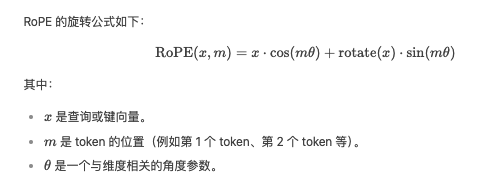

#### 3. **效果**
- 对于不同位置的相同 token（例如三个 "the"），RoPE 会生成不同的查询向量。
- 旋转后的查询向量既包含了 token 的语义信息，也包含了位置信息。

---

### 实现步骤
1. **输入**：
   - 查询向量：形状为 `[17x128]`（17 个 token，每个 token 的查询向量维度为 128）。
   - 位置信息：每个 token 的位置索引（例如 `[0, 1, 2, ..., 16]`）。

2. **旋转操作**：
   - 对每个 token 的查询向量应用 RoPE 旋转。
   - 旋转后的查询向量形状仍为 `[17x128]`，但每个向量现在包含了位置信息。

3. **输出**：
   - 旋转后的查询向量：形状为 `[17x128]`，每个 token 的查询向量根据其位置进行了调整。

---

### 示例
假设提示为：
```
"the answer to the ultimate question of life, the universe, and everything is "
```
- 三个 "the" 的位置分别为 0、2 和 7。
- 经过 RoPE 旋转后，三个 "the" 的查询向量会有所不同，因为它们的位置不同。

---

### 总结
- **RoPE** 是一种高效的位置编码方法，通过旋转向量的方式将位置信息注入到查询和键向量中。
- **作用**：确保相同 token 在不同位置具有不同的查询向量。
- **输出**：旋转后的查询向量形状仍为 `[17x128]`，但每个向量现在包含了位置信息。
<br><br>
### RoPE
看这个视频理解数学原理.
https://www.youtube.com/watch?v=o29P0Kpobz0&t=530s


<div>
    <img src="images/rope.png" width="600"/>
</div>

In [13]:
q_per_token_split_into_pairs = q_per_token.float().view(q_per_token.shape[0], -1, 2)
q_per_token_split_into_pairs.shape

torch.Size([17, 64, 2])

在上面的步骤中，我们将查询向量（query vectors）分成一对一对的，然后对每一对应用一个旋转角度偏移！

现在我们有一个形状为 `[17x64x2]` 的向量，这是将每个 token 的 128 维查询向量拆分为 64 对！每一对都会根据 token 的位置（`m`）旋转一个角度 `m * theta`，其中 `m` 是当前 token 的位置，`theta` 是预定义的旋转角度。

---

### 详细解释

1. **拆分查询向量**：
   - 原始查询向量的形状是 `[17, 128]`，其中：
     - `17` 是 prompt 中的 token 数量。
     - `128` 是每个 token 的查询向量的长度。
   - 我们将每个 128 维的查询向量拆分为 64 对（`128 / 2 = 64`），因此形状变为 `[17, 64, 2]`。

2. **旋转角度偏移**：
   - 对每一对查询向量（`[2]` 的形状），我们根据 token 的位置 `m` 旋转一个角度 `m * theta`。
   - `m` 是当前 token 的位置（例如，第一个 token 的 `m = 0`，第二个 token 的 `m = 1`，依此类推）。
   - `theta` 是一个预定义的角度值，通常与位置编码（positional encoding）相关。

3. **旋转的目的**：
   - 旋转操作是为了将位置信息（positional information）注入到查询向量中。
   - 这样，模型可以区分不同位置的 token，即使它们的查询向量在内容上相同。

4. **旋转的实现**：
   - 对于每一对 `[x, y]`，旋转角度 `m * theta` 后，新的值可以通过以下公式计算：
     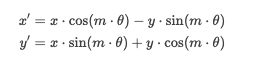
   - 这个公式是二维平面中向量的旋转公式。

5. **最终结果**：
   - 旋转后的查询向量仍然保持 `[17, 64, 2]` 的形状，但每一对的值已经根据 token 的位置进行了调整。

---

### 示例

假设：
- 有一个 prompt，包含 3 个 token。
- 每个 token 的查询向量长度为 4（为了简化，实际中是 128）。
- 预定义的 `theta = 0.1`。

1. **原始查询向量**：
   ```
   [
       [x1, y1, x2, y2],  # Token 1
       [x3, y3, x4, y4],  # Token 2
       [x5, y5, x6, y6]   # Token 3
   ]
   ```

2. **拆分为对**：
   ```
   [
       [[x1, y1], [x2, y2]],  # Token 1
       [[x3, y3], [x4, y4]],  # Token 2
       [[x5, y5], [x6, y6]]   # Token 3
   ]
   ```

3. **旋转操作**：
   - 对于 Token 1（`m = 0`），旋转角度为 `0 * theta = 0`，因此值不变。
   - 对于 Token 2（`m = 1`），旋转角度为 `1 * theta = 0.1`，对每一对 `[x, y]` 应用旋转公式。
   - 对于 Token 3（`m = 2`），旋转角度为 `2 * theta = 0.2`，对每一对 `[x, y]` 应用旋转公式。

4. **旋转后的结果**：
   ```
   [
       [[x1, y1], [x2, y2]],  # Token 1（未旋转）
       [[x3', y3'], [x4', y4']],  # Token 2（旋转 0.1）
       [[x5', y5'], [x6', y6']]   # Token 3（旋转 0.2）
   ]
   ```

---

### 总结
- 将查询向量拆分为对是为了方便对每一对应用旋转操作。
- 旋转操作将位置信息注入到查询向量中，使模型能够区分不同位置的 token。
- 最终结果是形状为 `[17, 64, 2]` 的旋转后的查询向量。


<div>
    <img src="images/qsplit.png" width="600"/>
</div>

## 使用复数的点积来旋转向量
<div>
    <img src="images/freq_cis.png" width="600"/>
</div>

In [14]:
zero_to_one_split_into_64_parts = torch.tensor(range(64))/64
zero_to_one_split_into_64_parts

tensor([0.0000, 0.0156, 0.0312, 0.0469, 0.0625, 0.0781, 0.0938, 0.1094, 0.1250,
        0.1406, 0.1562, 0.1719, 0.1875, 0.2031, 0.2188, 0.2344, 0.2500, 0.2656,
        0.2812, 0.2969, 0.3125, 0.3281, 0.3438, 0.3594, 0.3750, 0.3906, 0.4062,
        0.4219, 0.4375, 0.4531, 0.4688, 0.4844, 0.5000, 0.5156, 0.5312, 0.5469,
        0.5625, 0.5781, 0.5938, 0.6094, 0.6250, 0.6406, 0.6562, 0.6719, 0.6875,
        0.7031, 0.7188, 0.7344, 0.7500, 0.7656, 0.7812, 0.7969, 0.8125, 0.8281,
        0.8438, 0.8594, 0.8750, 0.8906, 0.9062, 0.9219, 0.9375, 0.9531, 0.9688,
        0.9844])

In [15]:
freqs = 1.0 / (rope_theta ** zero_to_one_split_into_64_parts)
freqs

tensor([1.0000e+00, 8.1462e-01, 6.6360e-01, 5.4058e-01, 4.4037e-01, 3.5873e-01,
        2.9223e-01, 2.3805e-01, 1.9392e-01, 1.5797e-01, 1.2869e-01, 1.0483e-01,
        8.5397e-02, 6.9566e-02, 5.6670e-02, 4.6164e-02, 3.7606e-02, 3.0635e-02,
        2.4955e-02, 2.0329e-02, 1.6560e-02, 1.3490e-02, 1.0990e-02, 8.9523e-03,
        7.2927e-03, 5.9407e-03, 4.8394e-03, 3.9423e-03, 3.2114e-03, 2.6161e-03,
        2.1311e-03, 1.7360e-03, 1.4142e-03, 1.1520e-03, 9.3847e-04, 7.6450e-04,
        6.2277e-04, 5.0732e-04, 4.1327e-04, 3.3666e-04, 2.7425e-04, 2.2341e-04,
        1.8199e-04, 1.4825e-04, 1.2077e-04, 9.8381e-05, 8.0143e-05, 6.5286e-05,
        5.3183e-05, 4.3324e-05, 3.5292e-05, 2.8750e-05, 2.3420e-05, 1.9078e-05,
        1.5542e-05, 1.2660e-05, 1.0313e-05, 8.4015e-06, 6.8440e-06, 5.5752e-06,
        4.5417e-06, 3.6997e-06, 3.0139e-06, 2.4551e-06])

tensor([[ 1.0000+0.0000e+00j,  1.0000+0.0000e+00j,  1.0000+0.0000e+00j,
          ...,  1.0000+0.0000e+00j,  1.0000+0.0000e+00j,
          1.0000+0.0000e+00j],
        [ 0.5403+8.4147e-01j,  0.6861+7.2746e-01j,  0.7878+6.1596e-01j,
          ...,  1.0000+3.6997e-06j,  1.0000+3.0139e-06j,
          1.0000+2.4551e-06j],
        [-0.4161+9.0930e-01j, -0.0584+9.9829e-01j,  0.2412+9.7048e-01j,
          ...,  1.0000+7.3994e-06j,  1.0000+6.0277e-06j,
          1.0000+4.9103e-06j],
        ...,
        [ 0.1367+9.9061e-01j,  0.3978-9.1749e-01j, -0.9910+1.3396e-01j,
          ...,  1.0000+5.1796e-05j,  1.0000+4.2194e-05j,
          1.0000+3.4372e-05j],
        [-0.7597+6.5029e-01j,  0.9404-3.4018e-01j, -0.8632-5.0488e-01j,
          ...,  1.0000+5.5496e-05j,  1.0000+4.5208e-05j,
          1.0000+3.6827e-05j],
        [-0.9577-2.8790e-01j,  0.8927+4.5066e-01j, -0.3690-9.2942e-01j,
          ...,  1.0000+5.9196e-05j,  1.0000+4.8222e-05j,
          1.0000+3.9282e-05j]])
torch.Size([17, 64])


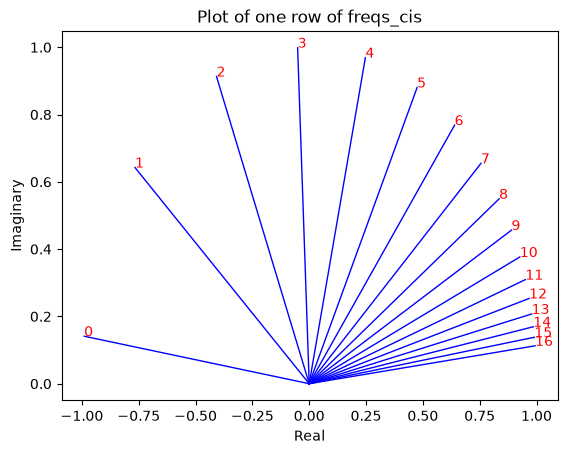

In [16]:
freqs_for_each_token = torch.outer(torch.arange(17), freqs)
freqs_cis = torch.polar(torch.ones_like(freqs_for_each_token), freqs_for_each_token)
print(freqs_cis)
print(freqs_cis.shape)

# viewing tjhe third row of freqs_cis
value = freqs_cis[3]
plt.figure()
for i, element in enumerate(value[:17]):
    plt.plot([0, element.real], [0, element.imag], color='blue', linewidth=1, label=f"Index: {i}")
    plt.annotate(f"{i}", xy=(element.real, element.imag), color='red')
plt.xlabel('Real')
plt.ylabel('Imaginary')
plt.title('Plot of one row of freqs_cis')
plt.show()

### 现在每一个token的query旋转向量

我们把query向量（划分为64对的）转化为复数，并且和旋转向量相乘


In [17]:
q_per_token_as_complex_numbers = torch.view_as_complex(q_per_token_split_into_pairs)
q_per_token_as_complex_numbers.shape

torch.Size([17, 64])

In [18]:
q_per_token_as_complex_numbers_rotated = q_per_token_as_complex_numbers * freqs_cis
q_per_token_as_complex_numbers_rotated.shape

torch.Size([17, 64])

### 在向量旋转之后
我们把复数向量再转化为实数向量

In [19]:
q_per_token_split_into_pairs_rotated = torch.view_as_real(q_per_token_as_complex_numbers_rotated)
q_per_token_split_into_pairs_rotated.shape

torch.Size([17, 64, 2])

我们现在有了考虑了位置的q向量 [17x128] 17 是tokens的数量  128 是每个向量的维度

In [20]:
q_per_token_rotated = q_per_token_split_into_pairs_rotated.view(q_per_token.shape)
q_per_token_rotated.shape

torch.Size([17, 128])

# keys (和queries几乎相同)
<div>
    <img src="images/keys.png" width="600px"/>
</div>

<br>
&gt; keys 维度也是 128
<br>
&gt; keys 只有 1/4th  queries 的量, 这个是因为GQA（分组注意力）
<br>
&gt; keys也有旋转，原理和queries相同

In [21]:
k_layer0 = model["layers.0.attention.wk.weight"]
k_layer0 = k_layer0.view(n_kv_heads, k_layer0.shape[0] // n_kv_heads, dim)
k_layer0.shape

torch.Size([8, 128, 4096])

In [22]:
k_layer0_head0 = k_layer0[0]
k_layer0_head0.shape

torch.Size([128, 4096])

In [23]:
k_per_token = torch.matmul(token_embeddings, k_layer0_head0.T)
k_per_token.shape

torch.Size([17, 128])

In [24]:
k_per_token_split_into_pairs = k_per_token.float().view(k_per_token.shape[0], -1, 2)
k_per_token_split_into_pairs.shape

torch.Size([17, 64, 2])

In [25]:
k_per_token_as_complex_numbers = torch.view_as_complex(k_per_token_split_into_pairs)
k_per_token_as_complex_numbers.shape

torch.Size([17, 64])

In [26]:
k_per_token_split_into_pairs_rotated = torch.view_as_real(k_per_token_as_complex_numbers * freqs_cis)
k_per_token_split_into_pairs_rotated.shape

torch.Size([17, 64, 2])

In [27]:
k_per_token_rotated = k_per_token_split_into_pairs_rotated.view(k_per_token.shape)
k_per_token_rotated.shape

torch.Size([17, 128])

## 现在我们有旋转后的q和k了
<div>
    <img src="images/keys0.png" width="600px"/>
</div>
q和k的维度为 [17x128]. 

## 下一步我们将Q和K相乘
得到注意力矩阵
<br>
这里面的分数就是相互影响的值. 
THIS IS SELF ATTENTION :)
<br>
注意力矩阵的维度是 (qk_per_token) is [17x17] 17 是输入序列的长度

<div>
    <img src="images/qkmatmul.png" width="600px"/>
</div>

In [28]:
qk_per_token = torch.matmul(q_per_token_rotated, k_per_token_rotated.T)/(head_dim)**0.5
qk_per_token.shape

torch.Size([17, 17])

# 现在要做mask

<br>
因为我们只能用前面的token去预测后面的token
<br>
所以，要把注意力矩阵中一半设置为0
<div>
    <img src="images/mask.png" width="600px"/>
</div>

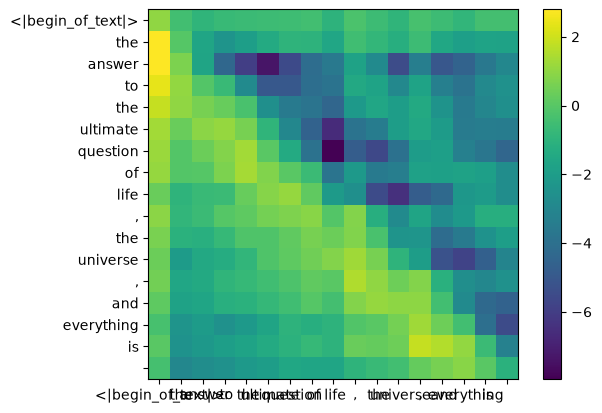

In [29]:
def display_qk_heatmap(qk_per_token):
    _, ax = plt.subplots()
    im = ax.imshow(qk_per_token.to(float).detach(), cmap='viridis')
    ax.set_xticks(range(len(prompt_split_as_tokens)))
    ax.set_yticks(range(len(prompt_split_as_tokens)))
    ax.set_xticklabels(prompt_split_as_tokens)
    ax.set_yticklabels(prompt_split_as_tokens)
    ax.figure.colorbar(im, ax=ax)
    
display_qk_heatmap(qk_per_token)

In [30]:
mask = torch.full((len(tokens), len(tokens)), float("-inf"), device=tokens.device)
mask = torch.triu(mask, diagonal=1)
mask

tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -in

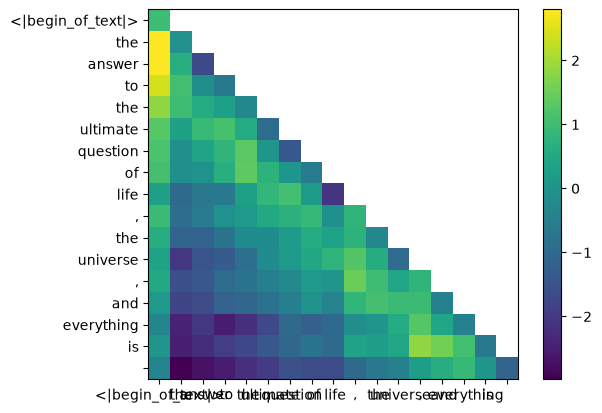

In [31]:
qk_per_token_after_masking = qk_per_token + mask
display_qk_heatmap(qk_per_token_after_masking)

<div>
    <img src="images/softmax.png" width="600px"/>
</div>

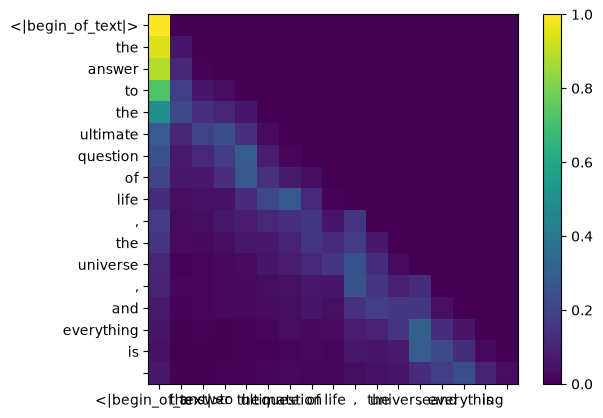

In [32]:
qk_per_token_after_masking_after_softmax = torch.nn.functional.softmax(qk_per_token_after_masking, dim=1).to(torch.bfloat16)
display_qk_heatmap(qk_per_token_after_masking_after_softmax)

## values 

<div>
    <img src="images/value.png" width="600px"/>
</div>
注意力得分(0-1) 用来决定每一个v向量被用多少
<br>
&gt; 和keys一样，要分组
<br>
&gt; Wv被切分为 [8x128x4096]


In [33]:
v_layer0 = model["layers.0.attention.wv.weight"]
v_layer0 = v_layer0.view(n_kv_heads, v_layer0.shape[0] // n_kv_heads, dim)
v_layer0.shape

torch.Size([8, 128, 4096])

第一个头的Wv如下

In [34]:
v_layer0_head0 = v_layer0[0]
v_layer0_head0.shape

torch.Size([128, 4096])

## value vectors
<div>
    <img src="images/v0.png" width="600px"/>
</div>
我们现在用原来模型的参数进行赋值, 维度为 [17x128] 

In [35]:
v_per_token = torch.matmul(token_embeddings, v_layer0_head0.T)
v_per_token.shape

torch.Size([17, 128])

## attention
<div>
    <img src="images/attention.png" width="600px"/>
</div>
每个序列在第一个头的v矩阵维度为 [17*128]

In [36]:
qkv_attention = torch.matmul(qk_per_token_after_masking_after_softmax, v_per_token)
qkv_attention.shape

torch.Size([17, 128])

# multi head attention（多头注意力）
<div>
    <img src="images/heads.png" width="600px"/>
</div>
到此为止第一层的第一个head都做完了
<br>
接下来跑个循环，做完所有的head

In [37]:
qkv_attention_store = []

for head in range(n_heads):
    q_layer0_head = q_layer0[head]
    k_layer0_head = k_layer0[head//4] # key weights are shared across 4 heads
    v_layer0_head = v_layer0[head//4] # value weights are shared across 4 heads
    q_per_token = torch.matmul(token_embeddings, q_layer0_head.T)
    k_per_token = torch.matmul(token_embeddings, k_layer0_head.T)
    v_per_token = torch.matmul(token_embeddings, v_layer0_head.T)

    q_per_token_split_into_pairs = q_per_token.float().view(q_per_token.shape[0], -1, 2)
    q_per_token_as_complex_numbers = torch.view_as_complex(q_per_token_split_into_pairs)
    q_per_token_split_into_pairs_rotated = torch.view_as_real(q_per_token_as_complex_numbers * freqs_cis[:len(tokens)])
    q_per_token_rotated = q_per_token_split_into_pairs_rotated.view(q_per_token.shape)

    k_per_token_split_into_pairs = k_per_token.float().view(k_per_token.shape[0], -1, 2)
    k_per_token_as_complex_numbers = torch.view_as_complex(k_per_token_split_into_pairs)
    k_per_token_split_into_pairs_rotated = torch.view_as_real(k_per_token_as_complex_numbers * freqs_cis[:len(tokens)])
    k_per_token_rotated = k_per_token_split_into_pairs_rotated.view(k_per_token.shape)

    qk_per_token = torch.matmul(q_per_token_rotated, k_per_token_rotated.T)/(128)**0.5
    mask = torch.full((len(tokens), len(tokens)), float("-inf"), device=tokens.device)
    mask = torch.triu(mask, diagonal=1)
    qk_per_token_after_masking = qk_per_token + mask
    qk_per_token_after_masking_after_softmax = torch.nn.functional.softmax(qk_per_token_after_masking, dim=1).to(torch.bfloat16)
    qkv_attention = torch.matmul(qk_per_token_after_masking_after_softmax, v_per_token)
    qkv_attention_store.append(qkv_attention)

len(qkv_attention_store)

32

<div>
    <img src="images/stacked.png" width="600px"/>
</div>
现在做完的32个头的,但是都是17*128，下面我们要把这32个头的合并起来 [17x4096]
<br>
we are almost at the end :)

In [38]:
stacked_qkv_attention = torch.cat(qkv_attention_store, dim=-1)
stacked_qkv_attention.shape

torch.Size([17, 4096])

# Wo
<div>
    <img src="images/weightmatrix.png" width="600px"/>
</div>
拼起来之后✖️Wo

In [39]:
w_layer0 = model["layers.0.attention.wo.weight"]
w_layer0.shape

torch.Size([4096, 4096])

### 矩阵相乘即可

In [40]:
embedding_delta = torch.matmul(stacked_qkv_attention, w_layer0.T)
embedding_delta.shape

torch.Size([17, 4096])

<div>
    <img src="images/afterattention.png" width="600px"/>
</div>
we now have the change in the embedding value after attention, that should be adding to the original token embeddings

In [41]:
embedding_after_edit = token_embeddings_unnormalized + embedding_delta
embedding_after_edit.shape

torch.Size([17, 4096])

## 正则化+FFN
<div>
    <img src="images/norm_after.png" width="600px"/>
</div>

In [42]:
embedding_after_edit_normalized = rms_norm(embedding_after_edit, model["layers.0.ffn_norm.weight"])
embedding_after_edit_normalized.shape

torch.Size([17, 4096])

## 加载ff 权重 并且进行前向传播
<div>
    <img src="images/swiglu.png" width="600px"/>
</div>
在 llama3, 使用 SwiGLU 作为激活函数, 
<br>


In [43]:
w1 = model["layers.0.feed_forward.w1.weight"]
w2 = model["layers.0.feed_forward.w2.weight"]
w3 = model["layers.0.feed_forward.w3.weight"]
output_after_feedforward = torch.matmul(torch.functional.F.silu(torch.matmul(embedding_after_edit_normalized, w1.T)) * torch.matmul(embedding_after_edit_normalized, w3.T), w2.T)
output_after_feedforward.shape

torch.Size([17, 4096])

# 在第一层之后，我们终于为每个标记都编辑了新的嵌入¶ 
- 在我们完成之前还有31层（一个for循环） 
- 你可以把这种编辑过的嵌入想象成拥有第一层所询问的所有查询的信息 
- 现在，每一层将对所问的问题进行越来越复杂的查询编码，直到我们有一个知道我们需要的下一个令牌的所有内容的嵌入。

In [44]:
layer_0_embedding = embedding_after_edit+output_after_feedforward
layer_0_embedding.shape

torch.Size([17, 4096])


<div>
    <img src="images/god.png" width="600px"/>
</div>
yep, this is it. everything we did before, all at once, for every single layer.
<br>



In [45]:
final_embedding = token_embeddings_unnormalized
for layer in range(n_layers):
    qkv_attention_store = []
    layer_embedding_norm = rms_norm(final_embedding, model[f"layers.{layer}.attention_norm.weight"])
    q_layer = model[f"layers.{layer}.attention.wq.weight"]
    q_layer = q_layer.view(n_heads, q_layer.shape[0] // n_heads, dim)
    k_layer = model[f"layers.{layer}.attention.wk.weight"]
    k_layer = k_layer.view(n_kv_heads, k_layer.shape[0] // n_kv_heads, dim)
    v_layer = model[f"layers.{layer}.attention.wv.weight"]
    v_layer = v_layer.view(n_kv_heads, v_layer.shape[0] // n_kv_heads, dim)
    w_layer = model[f"layers.{layer}.attention.wo.weight"]
    for head in range(n_heads):
        q_layer_head = q_layer[head]
        k_layer_head = k_layer[head//4]
        v_layer_head = v_layer[head//4]
        q_per_token = torch.matmul(layer_embedding_norm, q_layer_head.T)
        k_per_token = torch.matmul(layer_embedding_norm, k_layer_head.T)
        v_per_token = torch.matmul(layer_embedding_norm, v_layer_head.T)
        q_per_token_split_into_pairs = q_per_token.float().view(q_per_token.shape[0], -1, 2)
        q_per_token_as_complex_numbers = torch.view_as_complex(q_per_token_split_into_pairs)
        q_per_token_split_into_pairs_rotated = torch.view_as_real(q_per_token_as_complex_numbers * freqs_cis)
        q_per_token_rotated = q_per_token_split_into_pairs_rotated.view(q_per_token.shape)
        k_per_token_split_into_pairs = k_per_token.float().view(k_per_token.shape[0], -1, 2)
        k_per_token_as_complex_numbers = torch.view_as_complex(k_per_token_split_into_pairs)
        k_per_token_split_into_pairs_rotated = torch.view_as_real(k_per_token_as_complex_numbers * freqs_cis)
        k_per_token_rotated = k_per_token_split_into_pairs_rotated.view(k_per_token.shape)
        qk_per_token = torch.matmul(q_per_token_rotated, k_per_token_rotated.T)/(128)**0.5
        mask = torch.full((len(token_embeddings_unnormalized), len(token_embeddings_unnormalized)), float("-inf"))
        mask = torch.triu(mask, diagonal=1)
        qk_per_token_after_masking = qk_per_token + mask
        qk_per_token_after_masking_after_softmax = torch.nn.functional.softmax(qk_per_token_after_masking, dim=1).to(torch.bfloat16)
        qkv_attention = torch.matmul(qk_per_token_after_masking_after_softmax, v_per_token)
        qkv_attention_store.append(qkv_attention)

    stacked_qkv_attention = torch.cat(qkv_attention_store, dim=-1)
    w_layer = model[f"layers.{layer}.attention.wo.weight"]
    embedding_delta = torch.matmul(stacked_qkv_attention, w_layer.T)
    embedding_after_edit = final_embedding + embedding_delta
    embedding_after_edit_normalized = rms_norm(embedding_after_edit, model[f"layers.{layer}.ffn_norm.weight"])
    w1 = model[f"layers.{layer}.feed_forward.w1.weight"]
    w2 = model[f"layers.{layer}.feed_forward.w2.weight"]
    w3 = model[f"layers.{layer}.feed_forward.w3.weight"]
    output_after_feedforward = torch.matmul(torch.functional.F.silu(torch.matmul(embedding_after_edit_normalized, w1.T)) * torch.matmul(embedding_after_edit_normalized, w3.T), w2.T)
    final_embedding = embedding_after_edit+output_after_feedforward

# 现在就有了最终的embedding去预测下一个token
 token embeddings的维度是 [17x4096] 17  tokens 的序列长度， 4096 是 embedding dim
<div>
    <img src="images/last_norm.png" width="600px"/>
</div>

In [46]:
final_embedding = rms_norm(final_embedding, model["norm.weight"])
final_embedding.shape

torch.Size([17, 4096])

# 最后，对最后一个embedding进行解码
<div>
    <img src="images/finallayer.png" width="600px"/>
</div>
我们用output decoder 转化最后一个embedding为token

In [47]:
model["output.weight"].shape

torch.Size([128256, 4096])

# 我们用最后一个token的embedding去预测下一个token

In [48]:
logits = torch.matmul(final_embedding[-1], model["output.weight"].T)
logits.shape

torch.Size([128256])

In [49]:
next_token = torch.argmax(logits, dim=-1)
next_token

tensor(2983)

# lets fucking go
<div>
    <img src="images/42.png" width="600px"/>
</div>

In [50]:
tokenizer.decode([next_token.item()])

'42'